[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/05_supervised_gmm.py)

# Supervised Fitting vs. EM vs. CEM

This notebook compares three ways of fitting a `GaussianMixture` on the same synthetic data:

- **EM**: standard soft-assignment fitting, no label information.
- **CEM**: Classification EM -- hard assignment via `argmax(resp)` each iteration, no label information.
- **Supervised**: `fit(X, labels=y)` -- the assignment comes from the true label instead of `argmax(resp)`, converging in a single M-step (see the Supervised Fitting section of the [user guide](../user-guide/gaussian-mixture.md); the approach follows Celeux & Govaert 1992, McLachlan & Peel 2000 and Fraley & Raftery 2002).

The data reuses all 4 Gaussian components from [01 -- Gaussian Mixture Models](01_gmm.ipynb) (same centers, covariances and sample counts), but two of them share one label -- so there are only 3 classes even though there are 4 physical blobs. That is deliberate: EM and CEM don't see labels, so with `n_components=3` they are free to find whichever 3-way split fits the data best (which turns out *not* to match the label grouping), while the supervised fit is bound by the label and has to force a single Gaussian across two blobs it is told belong together. This is what makes the three methods diverge visibly instead of agreeing trivially.

**What you'll learn**

- How `fit(X, labels=y)` differs from unsupervised EM/CEM, and why it needs no iteration
- Why unsupervised components need not line up with class labels (and how `match_labels_to_true` handles arbitrary component indices)
- How to read misclassifications and 95% confidence regions in `plot_gmm` panels

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb) and [04 -- Classification EM](04_cem.ipynb).

**See also:** [18 -- Semi-Supervised and Positive-Unlabeled Fitting](18_semi_supervised_pu.ipynb), where only some labels are known.

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt


from tgmm import (
    GaussianMixture, plot_gmm, dynamic_figsize, generate_gmm_data,
    gmm_proxy, confidence_ellipse_std_devs, ClusteringMetrics,
)

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Data: 4 Gaussians from `01_gmm.ipynb`, 2 sharing one label

Same 4 centers/covariances/sample counts as in [01 -- Gaussian Mixture Models](01_gmm.ipynb). The
two spatially farthest-apart components -- `(2, -2)` and `(2, 2)`,
distance 4.0 -- share `Class 2`; `(0, 2)` and `(0, 0)` keep their own
labels. The *closest* pair, `(0, 2)` and `(0, 0)` (distance 2.0), is
exactly what an unsupervised 3-component fit tends to merge instead --
the opposite of the label grouping.

In [ ]:
centers = [
    np.array([0, 2]),
    np.array([0, 0]),
    np.array([2, -2]),
    np.array([2, 2]),
]
covs = [
    1.0 * np.eye(2),                    # spherical covariance
    np.array([[2, 0], [0, 0.5]]),       # diagonal covariance
    0.5 * np.eye(2),                    # spherical covariance, fewer points
    np.array([[0.2, 0.5], [0.5, 2]]),   # full covariance
]
n_samples = [800, 1000, 200, 1000]

# Components 2 and 3 (the two farthest apart, distance 4.0) share one
# label -- physical_to_label[i] is the class label for physical blob i.
physical_to_label = torch.tensor([0, 1, 2, 2])
n_components = 3
legend_labels = [f'Class {i}' for i in range(n_components)]

X_tensor, y_physical = generate_gmm_data(centers, covs, n_samples, device=device, random_state=SEED)
y_tensor = physical_to_label.to(y_physical.device)[y_physical]
X = X_tensor.cpu().numpy()
y_true = y_tensor.cpu().numpy()

## Fitting all three models

EM and CEM don't see `y_tensor` at all; only the supervised fit does.

In [ ]:
gmm_em = GaussianMixture(n_components=n_components, random_state=SEED)
t0 = time.time()
gmm_em.fit(X_tensor)
time_em = time.time() - t0

gmm_cem = GaussianMixture(n_components=n_components, random_state=SEED, algorithm='cem')
t0 = time.time()
gmm_cem.fit(X_tensor)
time_cem = time.time() - t0

gmm_sup = GaussianMixture(n_components=n_components)
t0 = time.time()
gmm_sup.fit(X_tensor, labels=y_tensor)
time_sup = time.time() - t0

print(f"EM:         iters={gmm_em.n_iter_:4d}  converged={gmm_em.converged_}  time={time_em:.4f}s  mean log-lik={gmm_em.score(X_tensor):.4f}")
print(f"CEM:        iters={gmm_cem.n_iter_:4d}  converged={gmm_cem.converged_}  time={time_cem:.4f}s  mean log-lik={gmm_cem.score(X_tensor):.4f}")
print(f"Supervised: iters={gmm_sup.n_iter_:4d}  converged={gmm_sup.converged_}  time={time_sup:.4f}s  mean log-lik={gmm_sup.score(X_tensor):.4f}")
print(f"\nSupervised gmm.classes_: {gmm_sup.classes_.cpu().tolist()}")

EM:         iters=  12  converged=True  time=0.0160s  mean log-lik=-3.4010
CEM:        iters=  16  converged=True  time=0.0217s  mean log-lik=-3.4166
Supervised: iters=   1  converged=True  time=0.0070s  mean log-lik=-3.4919

Supervised gmm.classes_: [0, 1, 2]


## Visual comparison

2x2 grid: true classes, EM, CEM, supervised. All four panels use the same 3
blue shades for `Class 0/1/2`, drawn entirely through `plot_gmm` -- no
hand-rolled matplotlib. The "True Classes" panel uses `gmm_proxy` to feed
the 4 true generating Gaussians (not a fitted model) into `plot_gmm`, with
`cluster_colors` repeating Class 2's blue for the two merged physical
components. EM/CEM component indices are arbitrary, so `match_labels_to_true`
Hungarian-matches them to the true labels for both point and ellipse
coloring; `show_incorrect_predictions` then colors correct points by their
matched cluster color and incorrect ones red -- so misclassifications are
directly visible, concentrated where the forced 3-way split disagrees with
the (arbitrary) label grouping. The supervised fit needs no matching, since
its component index already *is* the label (`classes_ == [0, 1, 2]`).
Ellipses are 95% confidence regions via `confidence_ellipse_std_devs(0.95)`
(Mahalanobis radius `sqrt(chi2.ppf(0.95, df=2))`, *not* "2 standard
deviations" -- that's a 1D interval, not a 2D confidence region), and
markers show each component's mean.

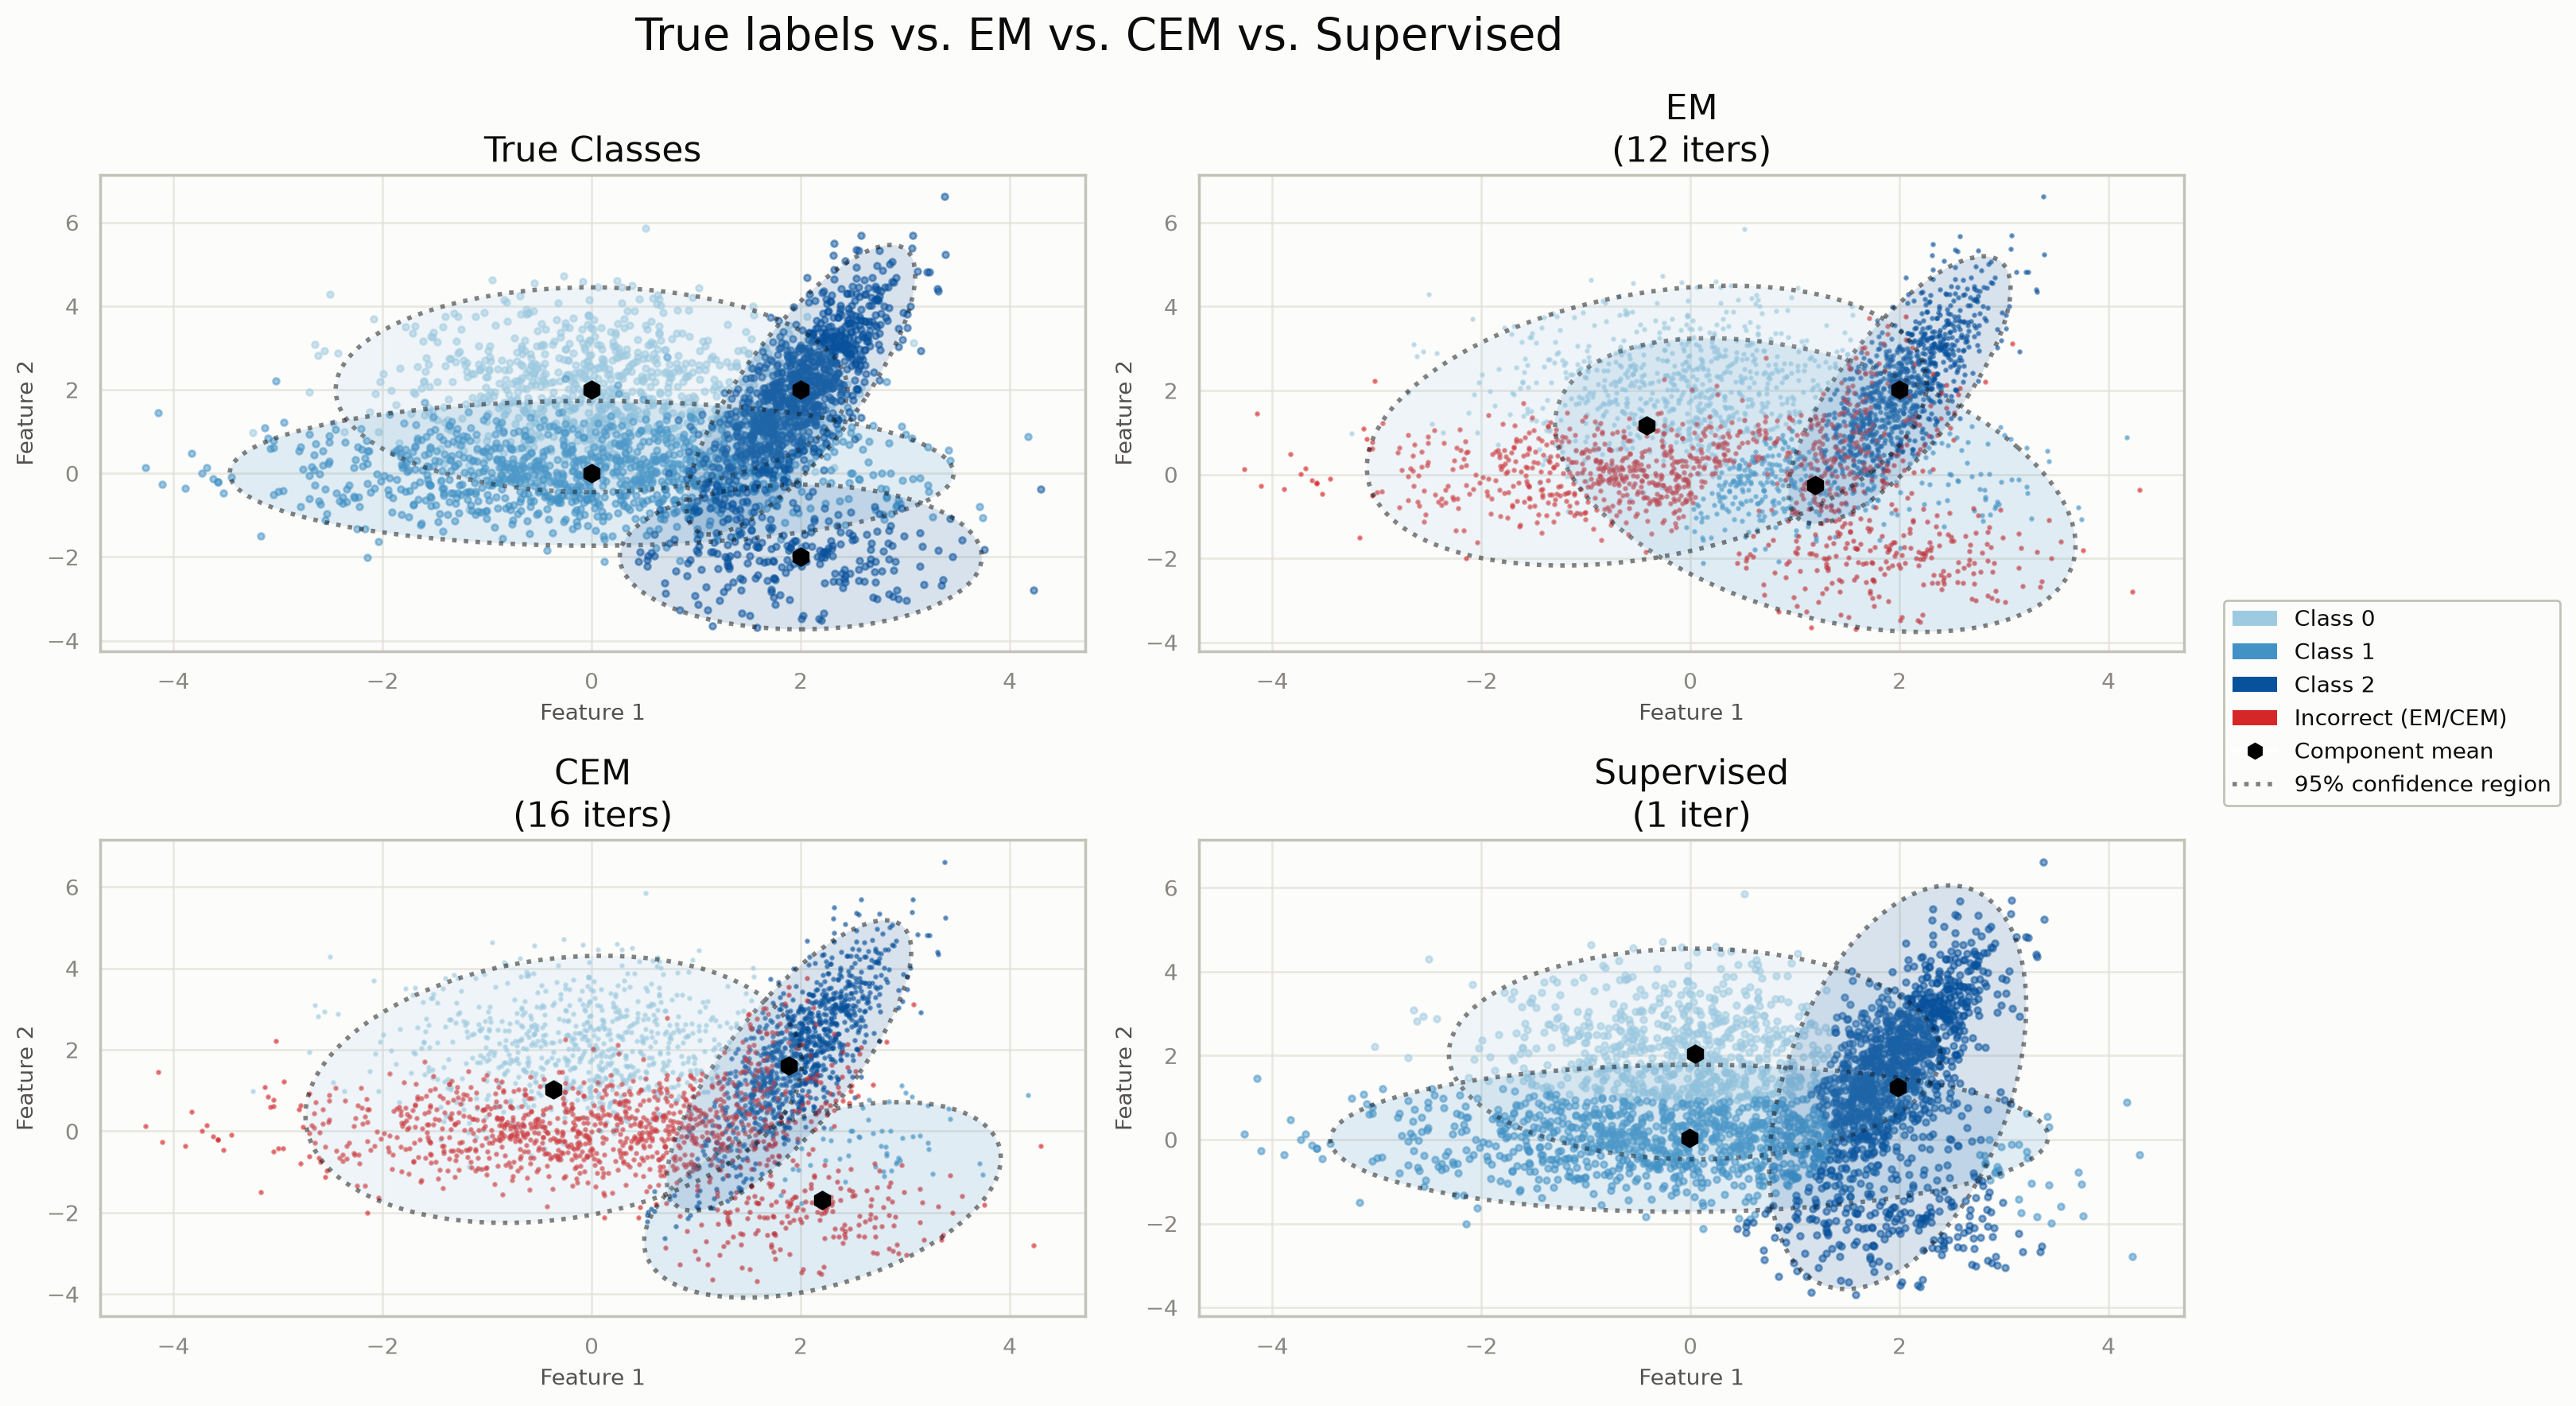

In [ ]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

BLUE_SHADES = ['#9ecae1', '#4292c6', '#08519c']  # Class 0, 1, 2
WRONG_COLOR = '#d62728'                          # incorrect predictions (EM/CEM only)
CONF_95 = confidence_ellipse_std_devs(0.95)      # chi2-based 95% CI multiplier, not "2 std devs"

ellipse_kwargs = dict(show_ellipses=True, ellipse_std_devs=CONF_95, ellipse_fill=True, ellipse_alpha=0.15)
mean_kwargs = dict(show_means=True, mean_color='black', mean_size=60)

fig, axes = plt.subplots(2, 2, figsize=dynamic_figsize(2, 2))
fig.suptitle('True labels vs. EM vs. CEM vs. Supervised')

# True classes: the 4 physical Gaussians via gmm_proxy (a stand-in `gmm=`
# object built from the raw generating parameters, not a fitted model),
# colored by the label each was folded into -- physical components 2 and 3
# both get Class 2's blue.
true_proxy = gmm_proxy(
    means=np.stack(centers), covariances=np.stack(covs),
    covariance_type='full', predicted_labels=y_physical,
)
true_cluster_colors = [BLUE_SHADES[label] for label in physical_to_label.tolist()]
plot_gmm(X=X, gmm=true_proxy, ax=axes[0, 0], title='True Classes',
         color_by_cluster=True, cluster_colors=true_cluster_colors,
         point_size=8, legend=False, **ellipse_kwargs, **mean_kwargs)

# EM / CEM: match_labels_to_true Hungarian-matches the arbitrary component
# indices to true labels for both point and ellipse coloring;
# show_incorrect_predictions colors correct points by their matched cluster
# color and incorrect ones in WRONG_COLOR.
plot_gmm(X=X, gmm=gmm_em, ax=axes[0, 1], title=f'EM\n({gmm_em.n_iter_} iters)',
         color_by_cluster=True, true_labels=y_true, match_labels_to_true=True,
         cluster_colors=BLUE_SHADES, show_incorrect_predictions=True, incorrect_color=WRONG_COLOR,
         point_size=8, legend=False, **ellipse_kwargs, **mean_kwargs)

plot_gmm(X=X, gmm=gmm_cem, ax=axes[1, 0], title=f'CEM\n({gmm_cem.n_iter_} iters)',
         color_by_cluster=True, true_labels=y_true, match_labels_to_true=True,
         cluster_colors=BLUE_SHADES, show_incorrect_predictions=True, incorrect_color=WRONG_COLOR,
         point_size=8, legend=False, **ellipse_kwargs, **mean_kwargs)

# Supervised: component index already is the label (classes_ == [0, 1, 2]),
# no Hungarian matching needed. Not correctness-colored (only EM/CEM get the
# red/blue treatment) -- points are colored by gmm_sup's own predict(),
# which by construction of the supervised fit matches the given label
# almost everywhere.
plot_gmm(X=X, gmm=gmm_sup, ax=axes[1, 1], title='Supervised\n(1 iter)',
         color_by_cluster=True, cluster_colors=BLUE_SHADES,
         point_size=8, legend=False, **ellipse_kwargs, **mean_kwargs)

legend_handles = (
    [Patch(facecolor=BLUE_SHADES[i], edgecolor='none', label=f'Class {i}') for i in range(n_components)]
    + [Patch(facecolor=WRONG_COLOR, edgecolor='none', label='Incorrect (EM/CEM)'),
       Line2D([0], [0], marker='h', color='w', markerfacecolor='black', markersize=9, label='Component mean'),
       Line2D([0], [0], color='gray', linestyle='dotted', linewidth=2, label='95% confidence region')]
)
fig.legend(handles=legend_handles, loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='small')

plt.tight_layout()
plt.gcf()

## Summary

- Supervised fitting (`fit(X, labels=y)`) takes the assignment from the labels, so one M-step already gives the per-class mean, covariance and weight; `n_iter_` is always 1.
- EM and CEM never see the labels, so with a label grouping that disagrees with the data's geometry they find a different 3-way split.
- Unsupervised component indices are arbitrary; `match_labels_to_true=True` Hungarian-matches them to the labels so errors can be visualized.
- Supervised fits trade the flexibility of unsupervised fitting for fidelity to the labels -- useful when the labels are trusted.

**Next:** [18 -- Semi-Supervised and Positive-Unlabeled Fitting](18_semi_supervised_pu.ipynb) for partially labeled data, or [06 -- Clustering Metrics](06_metrics.ipynb) to quantify agreement with labels.